# Visual Branch Folder Exploration

This notebook visualizes and explains every part of the `visual_branch` folder, including its structure, file types, and statistics. Use this as a comprehensive overview and diagnostic tool for your project pipeline.

In [1]:
!pip install humanize


[notice] A new release of pip is available: 25.1.1 -> 26.0.1
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 25.1.1 -> 26.0.1
[notice] To update, run: pip install --upgrade pip


In [2]:
# Import Required Libraries
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import humanize
import sys
def get_size(path):
    total = 0
    for entry in os.scandir(path):
        if entry.is_file():
            total += entry.stat().st_size
        elif entry.is_dir():
            total += get_size(entry.path)
    return total

In [3]:
# Set the path to the visual branch folder
visual_branch_path = Path('visual_branch')
print(f"Visual branch folder: {visual_branch_path.resolve()}")

Visual branch folder: /Users/shubhbhateja/College/minor_project/visual_branch


In [12]:
# Recursively list all files and folders
all_files = []
for root, dirs, files in os.walk(visual_branch_path):
    for name in files:
        file_path = Path(root) / name
        all_files.append({
            'path': file_path,
            'size': file_path.stat().st_size,
            'extension': file_path.suffix.lower(),
            'is_file': True
        })
    for name in dirs:
        dir_path = Path(root) / name
        all_files.append({
            'path': dir_path,
            'size': get_size(dir_path),
            'extension': '',
            'is_file': False
        })
files_df = pd.DataFrame(all_files)
files_df.head(20)

,path,size,extension,is_file
0,visual_branch/smoke_test.py,1667,.py,True
1,visual_branch/model_integration.py,4948,.py,True
2,visual_branch/preprocess.py,4749,.py,True
3,visual_branch/data_loader.py,7142,.py,True
4,visual_branch/train.py,7348,.py,True
5,visual_branch/data_generator.py,6392,.py,True
6,visual_branch/model_1dcnn.py,2656,.py,True
7,visual_branch/__pycache__,36249,,False
8,visual_branch/__pycache__/data_loader.cpython-...,9379,.pyc,True
9,visual_branch/__pycache__/data_loader.cpython-...,8262,.pyc,True


In [5]:
# Visualize folder structure as a tree
def print_tree(start_path, prefix=""):
    items = sorted(os.listdir(start_path))
    pointers = ["├── "] * (len(items) - 1) + ["└── "]
    for pointer, item in zip(pointers, items):
        path = os.path.join(start_path, item)
        print(prefix + pointer + item)
        if os.path.isdir(path):
            extension = "│   " if pointer == "├── " else "    "
            print_tree(path, prefix + extension)
print(f"Folder structure for: {visual_branch_path}")
print_tree(str(visual_branch_path))

Folder structure for: visual_branch
├── __pycache__
│   ├── data_generator.cpython-311.pyc
│   ├── data_generator.cpython-313.pyc
│   ├── data_loader.cpython-311.pyc
│   ├── data_loader.cpython-313.pyc
│   └── model_integration.cpython-311.pyc
├── data_generator.py
├── data_loader.py
├── model_1dcnn.py
├── model_integration.py
├── preprocess.py
├── smoke_test.py
└── train.py


In [6]:
# Display file and folder statistics
total_files = files_df[files_df['is_file']].shape[0]
total_dirs = files_df[~files_df['is_file']].shape[0]
total_size = files_df[files_df['is_file']]['size'].sum()
print(f"Total files: {total_files}")
print(f"Total folders: {total_dirs}")
print(f"Total size: {humanize.naturalsize(total_size)}")

Total files: 12
Total folders: 1
Total size: 71.2 kB


/var/folders/_3/gpn706_55jl6456txw85jj5w0000gn/T/ipykernel_20340/857823435.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=file_types.index, y=file_types.values, palette='viridis')


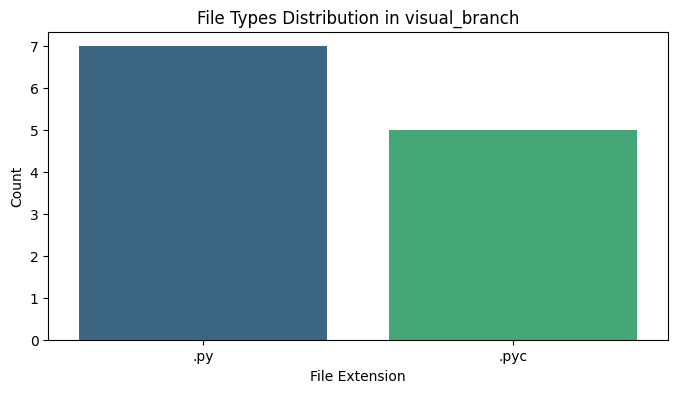

In [7]:
# Visualize file types distribution
file_types = files_df[files_df['is_file']]['extension'].value_counts()
plt.figure(figsize=(8,4))
sns.barplot(x=file_types.index, y=file_types.values, palette='viridis')
plt.title('File Types Distribution in visual_branch')
plt.xlabel('File Extension')
plt.ylabel('Count')
plt.show()

In [8]:
# Show largest files in the folder
largest_files = files_df[files_df['is_file']].sort_values('size', ascending=False).head(10)
largest_files['size_human'] = largest_files['size'].apply(humanize.naturalsize)
largest_files[['path', 'size_human']]

,path,size_human
8,visual_branch/__pycache__/data_loader.cpython-...,9.4 kB
9,visual_branch/__pycache__/data_loader.cpython-...,8.3 kB
12,visual_branch/__pycache__/data_generator.cpyth...,7.7 kB
4,visual_branch/train.py,7.3 kB
3,visual_branch/data_loader.py,7.1 kB
11,visual_branch/__pycache__/data_generator.cpyth...,7.1 kB
5,visual_branch/data_generator.py,6.4 kB
1,visual_branch/model_integration.py,4.9 kB
2,visual_branch/preprocess.py,4.7 kB
10,visual_branch/__pycache__/model_integration.cp...,3.8 kB


In [9]:
# Optional: Export folder structure or statistics to a CSV file
export_path = visual_branch_path.parent / 'visual_branch_file_stats.csv'
files_df.to_csv(export_path, index=False)
print(f"Exported file statistics to {export_path}")

Exported file statistics to visual_branch_file_stats.csv
